# SI: resonance through $\beta_1$ — which state to monitor

Supplementary to Figure 2 (panel E). The resonance strategy switches the spring
constant $k=\alpha\beta_1$ between a hard and a soft value. Figure 2 does it
through $\alpha$, whose conjugate state is $B-\mu$ ($\partial E/\partial\alpha \sim (B-\mu)^2$),
so the controller watches $B$. Here the knob is $\beta_1$ instead, whose
conjugate is $A$ ($\partial E/\partial\beta_1 \sim A^2$): the controller has to
monitor $A$, and monitoring $B$ fails. The last pair repeats the comparison
through $\alpha$, where the roles swap.

Figures (written to `plots/`):

* `figure2_SI_panelE_beta1.pdf` (+ `_legend`) — panel E with $\beta_1$ as the knob
* `figure2_SI_beta1_watch_B.pdf` — switching $\beta_1$ while monitoring $B$ (wrong conjugate)
* `figure2_SI_beta1_watch_A.pdf` — switching $\beta_1$ while monitoring $A$
* `figure2_SI_alpha_watch_A.pdf` — switching $\alpha$ while monitoring $A$ (wrong conjugate)
* `figure2_SI_alpha_watch_B.pdf` — switching $\alpha$ while monitoring $B$
* `figure2_SI_alpha_legend.pdf` — key for the $\alpha$ pair's grey shading

In [13]:
"""SI resonance monitor — shared imports and plotting style."""
import sys
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

sys.path.insert(0, '../src')
from rpa_control.style import set_style
from rpa_control.paths import save_fig

set_style()


In [14]:
# ======================================================================
# Plotting helpers (copied from figure2.ipynb)
# ======================================================================

SHADE_COLOR = '0.93'   # grey == soft spring, as in figure 2

def shade_spring(ax, t, ctrl, hard_val, soft_val):
    """Shade the time windows in which the soft spring is engaged.

    Grey means "soft spring" throughout figure 2: the post-switch span in
    panel B (beta1 halves, so k = alpha*beta1 drops) and the soft phases of
    the bang-bang schedule here.
    """
    is_soft = np.isclose(ctrl, soft_val)
    changes = np.where(np.diff(is_soft.astype(int)) != 0)[0]
    boundaries = np.concatenate([[0], changes + 1, [len(t) - 1]])
    for j in range(len(boundaries) - 1):
        i0, i1 = boundaries[j], boundaries[j + 1]
        if is_soft[i0]:
            ax.axvspan(t[i0], t[i1], color=SHADE_COLOR, lw=0)

def spring_legend(hard_label, soft_label, figsize=(1.0, 3.2), fontsize=11):
    """Tall, narrow key for the background shading: white = hard, grey = soft.

    Two large blocks stacked in a column, each labelled inside, so the swatches
    carry the same tone the panels use at a size that is actually readable. Its
    own figure, so it can sit beside a panel without eating axis space. The
    labels are arguments because the switched parameter differs by panel:
    beta1 in panel B, alpha in E/G/F/H.
    """
    gap = 0.05                       # sliver of page between the two blocks
    fig, ax = plt.subplots(figsize=figsize)
    for y0, face, label in [(1 + gap, 'white', hard_label),
                            (0.0, SHADE_COLOR, soft_label)]:
        ax.add_patch(Rectangle((0, y0), 1, 1 - gap, facecolor=face,
                               edgecolor='0.8', lw=0.8))
        ax.text(0.5, y0 + (1 - gap) / 2, label, ha='center', va='center',
                fontsize=fontsize, linespacing=1.5)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 2 + gap)
    ax.set_axis_off()
    fig.tight_layout(pad=0.05)
    return fig

# ======================================================================
# Dynamics (copied from figure2.ipynb)
# ======================================================================

def rk4_step(f, y, dt):
    k1 = f(y); k2 = f(y + 0.5*dt*k1)
    k3 = f(y + 0.5*dt*k2); k4 = f(y + dt*k3)
    return y + (dt/6.0) * (k1 + 2*k2 + 2*k3 + k4)

def adaptive_alpha(B, Bdot, alpha_hard, alpha_soft, eq):
    """Adaptive spring strategy:
    - Hard spring when moving toward equilibrium (accelerate return)
    - Soft spring when moving away from equilibrium (reduce overshoot)

    In general this is "hard while |B - eq| is falling", i.e. hard iff
    (B - eq) * Bdot < 0. Nothing here requires B to be the regulated variable:
    a caller that needs to watch some other state x passes (x, x_dot, hard,
    soft, 0.0). See run_adaptive_calcium_param.
    """
    if B > eq:
        return alpha_hard if Bdot < 0 else alpha_soft
    else:
        return alpha_hard if Bdot > 0 else alpha_soft

mu = 1.0       # equilibrium setpoint
T = 10.0       # simulation horizon
dt = 0.005     # RK4 timestep for adaptive simulations

def penalty_below(B, radius=0.0, eq=mu):
    """One-sided kill signal: active while B sits below eq - radius."""
    return np.maximum((eq - B) - radius, 0.0)

def minimal_rhs(y, alpha, beta1, beta2, c1, c2, radius=0.0, penalty=penalty_below):
    """Integral feedback (A, B) plus a tumour C that shrinks while the
    kill signal is on. C does not feed back into A or B, so B(t) is
    identical for every choice of `penalty`, c1 and c2."""
    A, B, C = y
    return np.array([alpha * (mu - B),
                     beta1 * A - beta2 * B,
                     C * (c1 - c2 * penalty(B, radius))])

# ======================================================================
# Switching beta1
# ======================================================================

# --- SI: the same strategy run through beta1 instead of alpha ---
#     k = alpha*beta1 either way, but the conjugate states differ: dE/dalpha
#     goes with (B - mu)^2 while dE/dbeta1 goes with A^2, so switching beta1
#     means watching A. The two are a quarter cycle apart -- equivalently, the
#     protocols are inverses of each other, since the modulation is a square
#     wave at 2*omega. A is watched raw: A* = beta2*mu/beta1 moves with the
#     switched parameter, and referencing it costs rate and chatters.
SI_BETA1 = dict(
    alpha=1.0, beta2=1.0,
    c1=0.1, c2=1.0,
    beta1_hard=50.0, beta1_soft=10.0,     # same k swing as PANEL_E, 10 <-> 50
    #  Threshold the controller compares A against. A settles somewhere in
    #  [beta2*mu/beta1_hard, beta2*mu/beta1_soft] = [0.02, 0.10] depending on
    #  which beta1 is engaged, and a threshold INSIDE that interval gets
    #  straddled by the equilibrium drift itself: the rule then switches for
    #  reasons unrelated to phase, chatters, and anti-pumps. Anything at or
    #  below the lower end works; 0.02 is that lower end, beta2*mu/beta1_hard.
    A_thresh=0.02,
    x0=[0.0, 0.0, 1.0],
)

def run_adaptive_beta1(p, penalty=penalty_below, watch='A'):
    """Bang-bang beta1 driven by the sign of A*Adot: the panel E strategy with
    the other half of the spring constant as the knob.

    `watch` selects the state the controller keys on -- 'A', the conjugate of
    beta1, or 'B', the conjugate of alpha. Only 'A' pumps; 'B' is the wrong
    conjugate here and is kept so the SI can show the failure."""
    radius = p.get('radius', 0.0)
    n_steps = int(T / dt)
    t_arr = np.linspace(0, T, n_steps + 1)
    y = np.zeros((n_steps + 1, 3)); y[0] = p['x0']
    beta1_t = np.zeros(n_steps + 1)
    bi = np.sqrt(p['beta1_hard'] * p['beta1_soft'])
    for i in range(n_steps):
        A, B, C = y[i]
        if watch == 'A':
            bi = adaptive_alpha(A, p['alpha'] * (mu - B),
                                p['beta1_hard'], p['beta1_soft'],
                                p.get('A_thresh', 0.0))
        else:
            bi = adaptive_alpha(B, bi * A - p['beta2'] * B,
                                p['beta1_hard'], p['beta1_soft'], mu)
        beta1_t[i] = bi
        y[i+1] = rk4_step(
            lambda y_: minimal_rhs(y_, p['alpha'], bi, p['beta2'], p['c1'], p['c2'],
                                   radius=radius, penalty=penalty),
            y[i], dt)
    beta1_t[-1] = beta1_t[-2]
    return dict(t=t_arr, y=y, ctrl=beta1_t, beta1=beta1_t)

**SI: panel E through $\beta_1$** — The same resonance strategy with $\beta_1$
as the knob instead of $\alpha$. The spring constant is $k=\alpha\beta_1$ either
way, but the conjugate states differ — $\partial E/\partial\alpha \sim (B-\mu)^2$
against $\partial E/\partial\beta_1 \sim A^2$ — so the controller watches $A$.
What is plotted is still $B$, the regulated variable, as in panel E.

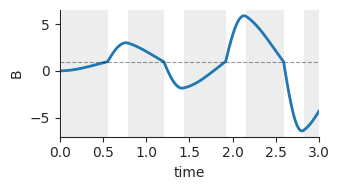

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_SI_panelE_beta1.pdf


In [15]:
# SI: panel E, but switching beta1 and watching A. B, the regulated variable,
# is what is plotted, as in panel E and the alpha pair below.
# Grey still marks the soft spring, here beta1_soft. The dashed line is mu.
T_SI = 3.0
data_SI_b1 = run_adaptive_beta1(SI_BETA1)
win = data_SI_b1['t'] <= T_SI

fig, ax = plt.subplots(1, 1, figsize=(3.5, 2))

ax_B = ax

shade_spring(ax_B, data_SI_b1['t'][win], data_SI_b1['beta1'][win],
             SI_BETA1['beta1_hard'], SI_BETA1['beta1_soft'])

ax_B.plot(data_SI_b1['t'][win], data_SI_b1['y'][win, 1], lw=2, color='C0',
          label='Adaptive switching')
ax_B.axhline(mu, color='black', ls='--', lw=0.8, alpha=0.4)
ax_B.set_ylabel('B')
ax.set_xlabel('time')
ax.set_xlim(0, T_SI)

sns.despine(ax=ax)

plt.tight_layout()
plt.show()

save_fig(fig, 'figure2_SI_panelE_beta1.pdf')

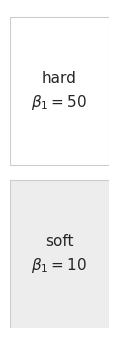

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_SI_panelE_beta1_legend.pdf


In [16]:
# Key for the grey background in the SI beta1 panel: grey == soft spring.
# Same helper and same convention as the panel E key, with beta1 as the knob.
# Values come from SI_BETA1, so the key cannot drift from the simulation.
fig = spring_legend(
    hard_label=f"hard\n$\\beta_1 = {SI_BETA1['beta1_hard']:g}$",
    soft_label=f"soft\n$\\beta_1 = {SI_BETA1['beta1_soft']:g}$")
plt.show()

save_fig(fig, 'figure2_SI_panelE_beta1_legend.pdf')

**Monitoring the right state** — $\beta_1$ is switched in both runs, with the
same swing, criterion and initial state; they differ only in the state the
controller keys on. Monitoring $B$ (the conjugate of $\alpha$) fails, monitoring
$A$ (the conjugate of $\beta_1$) pumps.

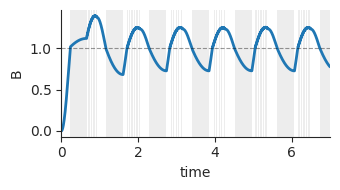

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_SI_beta1_watch_B.pdf


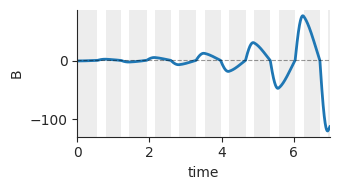

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_SI_beta1_watch_A.pdf


In [17]:
# SI: the conjugate-state point, made on the AB model instead of the calcium one.
# beta1 is the switched parameter in BOTH figures -- the same 10 <-> 50 swing,
# the same criterion, the same initial state. They differ only in which state
# the controller keys on:
#     dE/dalpha ~ (B - mu)^2      dE/dbeta1 ~ A^2
# so A is beta1's conjugate and B is alpha's. Watching B while switching beta1
# is a quarter cycle off, and it does not merely under-pump: it fails outright,
# and chatters besides, because beta1 sits directly in Bdot so a switch can
# reverse B's direction of travel and re-trigger the rule.
# B, the regulated variable, is plotted in both, whichever state is watched.
# Own window, longer than the single-panel figure above: the divergence needs a
# few more cycles to be unmistakable (watching B, B stays within 0.73-1.25;
# watching A, it swings from -120 to 78 by t = 7). The dashed line is mu.
T_CONJ = 7.0

runs = [('B', 'watch_B', "monitoring $B$  —  $\\alpha$'s conjugate, wrong here"),
        ('A', 'watch_A', "monitoring $A$  —  $\\beta_1$'s conjugate")]

for watch, tag, title in runs:
    d = run_adaptive_beta1(SI_BETA1, watch=watch)
    w = d['t'] <= T_CONJ

    fig, ax = plt.subplots(1, 1, figsize=(3.5, 2))

    shade_spring(ax, d['t'][w], d['beta1'][w],
                 SI_BETA1['beta1_hard'], SI_BETA1['beta1_soft'])
    ax.plot(d['t'][w], d['y'][w, 1], lw=2, color='C0')
    ax.axhline(mu, color='black', ls='--', lw=0.8, alpha=0.4)
#     ax.set_title(title, fontsize=8, loc='left')
    ax.set_ylabel('B')
    ax.set_xlabel('time')
    ax.set_xlim(0, T_CONJ)
    sns.despine(ax=ax)

    plt.tight_layout()
    plt.show()

    save_fig(fig, f'figure2_SI_beta1_{tag}.pdf')

**The same comparison through $\alpha$** — now $\alpha$ is switched in both
runs, over the same $k$ swing ($10 \leftrightarrow 50$) and from the same initial
state. The roles swap: $B$ is $\alpha$'s conjugate, so monitoring $B$ pumps and
monitoring $A$ fails. $B$ is what is plotted.

In [18]:
# --- SI: switching alpha, monitoring either state ---
#     The mirror image of SI_BETA1: the same k swing 10 <-> 50, now carried by
#     alpha with beta1 fixed, and the same initial state. Unlike the beta1
#     case, A's equilibrium A* = beta2*mu/beta1 does not move with the switched
#     parameter, so A can be watched against A* directly -- no threshold
#     tuning, and no chatter, since alpha enters Adot = alpha*(mu - B) only as
#     a positive factor and a switch never flips Adot's sign.
SI_ALPHA = dict(
    beta1=1.0, beta2=1.0,
    c1=0.1, c2=1.0,
    alpha_hard=50.0, alpha_soft=10.0,     # same k swing as SI_BETA1
    x0=[0.0, 0.0, 1.0],
)

def run_adaptive_alpha(p, penalty=penalty_below, watch='B'):
    """Bang-bang alpha driven by the sign of (x - x*)*xdot for the watched
    state x: 'B', the conjugate of alpha (watched against mu), or 'A', the
    conjugate of beta1 (watched against A*). Only 'B' pumps; 'A' is the wrong
    conjugate here and is kept so the SI can show the failure."""
    radius = p.get('radius', 0.0)
    n_steps = int(T / dt)
    t_arr = np.linspace(0, T, n_steps + 1)
    y = np.zeros((n_steps + 1, 3)); y[0] = p['x0']
    alpha_t = np.zeros(n_steps + 1)
    A_star = p['beta2'] * mu / p['beta1']
    for i in range(n_steps):
        A, B, C = y[i]
        if watch == 'B':
            ai = adaptive_alpha(B, p['beta1'] * A - p['beta2'] * B,
                                p['alpha_hard'], p['alpha_soft'], mu)
        else:
            # sign of Adot = alpha*(mu - B) is that of (mu - B) for any alpha > 0
            ai = adaptive_alpha(A, mu - B,
                                p['alpha_hard'], p['alpha_soft'], A_star)
        alpha_t[i] = ai
        y[i+1] = rk4_step(
            lambda y_: minimal_rhs(y_, ai, p['beta1'], p['beta2'], p['c1'], p['c2'],
                                   radius=radius, penalty=penalty),
            y[i], dt)
    alpha_t[-1] = alpha_t[-2]
    return dict(t=t_arr, y=y, ctrl=alpha_t, alpha=alpha_t)

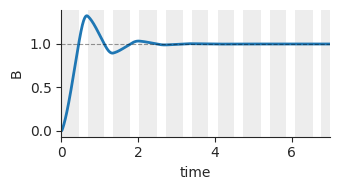

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_SI_alpha_watch_A.pdf


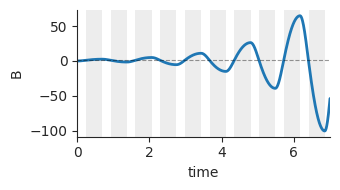

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_SI_alpha_watch_B.pdf


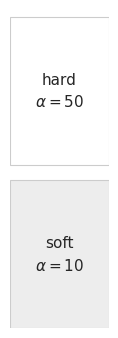

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_SI_alpha_legend.pdf


In [19]:
# SI: the conjugate-state point through alpha -- the mirror of the beta1 pair
# above. alpha is switched in BOTH figures, same swing, same initial state; they
# differ only in which state the controller keys on. Watching B (alpha's
# conjugate) pumps: |B - mu| grows from ~1.6 to ~100 by t = 7. Watching A
# (beta1's conjugate) is a quarter cycle off and damps instead: B is back at mu
# to within 0.001 by t = 5.
# Same window as the beta1 pair so the two sets read side by side. The dashed
# line is mu, the setpoint, which is also the B-watcher's switching threshold.
runs_alpha = [('A', 'watch_A', "monitoring $A$  —  $\\beta_1$'s conjugate, wrong here"),
              ('B', 'watch_B', "monitoring $B$  —  $\\alpha$'s conjugate")]

for watch, tag, title in runs_alpha:
    d = run_adaptive_alpha(SI_ALPHA, watch=watch)
    w = d['t'] <= T_CONJ

    fig, ax = plt.subplots(1, 1, figsize=(3.5, 2))

    shade_spring(ax, d['t'][w], d['alpha'][w],
                 SI_ALPHA['alpha_hard'], SI_ALPHA['alpha_soft'])
    ax.plot(d['t'][w], d['y'][w, 1], lw=2, color='C0')
    ax.axhline(mu, color='black', ls='--', lw=0.8, alpha=0.4)
#     ax.set_title(title, fontsize=8, loc='left')
    ax.set_ylabel('B')
    ax.set_xlabel('time')
    ax.set_xlim(0, T_CONJ)
    sns.despine(ax=ax)

    plt.tight_layout()
    plt.show()

    save_fig(fig, f'figure2_SI_alpha_{tag}.pdf')

# Key for the grey background in the alpha pair: grey == soft spring.
fig = spring_legend(
    hard_label=f"hard\n$\\alpha = {SI_ALPHA['alpha_hard']:g}$",
    soft_label=f"soft\n$\\alpha = {SI_ALPHA['alpha_soft']:g}$")
plt.show()

save_fig(fig, 'figure2_SI_alpha_legend.pdf')